In [ ]:
import pandas as pd
import matplotlib.pyplot as plt

df = pd.read_csv("tracker.csv")
df.columns = df.columns.str.strip().str.lower()   # tidy column names
df["date"] = pd.to_datetime(df["date"], format="%d.%m.%y")

print(df.head())
print(df.dtypes)
print("Dates:", df["date"].min(), "to", df["date"].max())
print("Missing values:\n", df.isna().sum())

        date  caffeine_mg  sleep_hours  exam_season wake_time bedtime  \
0 2026-09-01         42.0          9.5            0       NaN     NaN   
1 2026-09-02        102.0          8.5            0       NaN     NaN   
2 2026-09-03         95.0          8.5            0       NaN     NaN   
3 2026-09-04         84.0          6.0            0       NaN     NaN   
4 2026-09-05         80.0         11.0            0       NaN     NaN   

   alarm_set  
0        NaN  
1        NaN  
2        NaN  
3        NaN  
4        NaN  
date           datetime64[ns]
caffeine_mg           float64
sleep_hours           float64
exam_season             int64
wake_time              object
bedtime                object
alarm_set             float64
dtype: object
Dates: 2026-09-01 00:00:00 to 2026-10-19 00:00:00
Missing values:
 date            0
caffeine_mg     3
sleep_hours     6
exam_season     0
wake_time      29
bedtime        42
alarm_set      40
dtype: int64


In [ ]:
df = df.dropna(subset=["sleep_hours", "caffeine_mg"])
print(len(df), "usable days")
df[["caffeine_mg", "sleep_hours"]].describe()

42 usable days


,caffeine_mg,sleep_hours
count,42.000000,42.000000
mean,57.428571,7.583333
std,29.574332,2.804432
min,0.000000,2.000000
25%,41.250000,5.500000
50%,62.500000,7.250000
75%,84.000000,9.000000
max,104.000000,14.000000


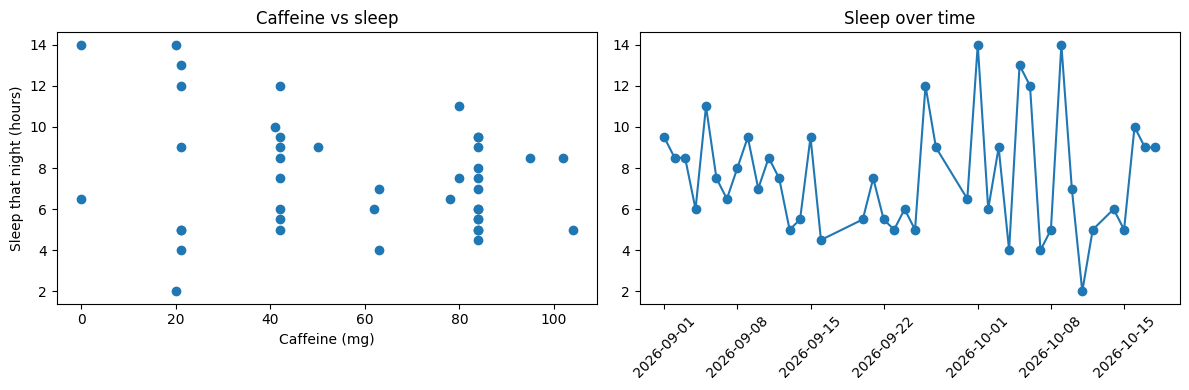

In [ ]:
fig, ax = plt.subplots(1, 2, figsize=(12, 4))

ax[0].scatter(df["caffeine_mg"], df["sleep_hours"])
ax[0].set_xlabel("Caffeine (mg)")
ax[0].set_ylabel("Sleep that night (hours)")
ax[0].set_title("Caffeine vs sleep")

ax[1].plot(df["date"], df["sleep_hours"], marker="o")
ax[1].set_title("Sleep over time")
ax[1].tick_params(axis="x", rotation=45)

plt.tight_layout()
plt.show()

In [ ]:
print(df[["caffeine_mg", "sleep_hours", "exam_season"]].corr())

print("\nAverage by exam season (1 = exams):")
print(df.groupby("exam_season")[["caffeine_mg", "sleep_hours"]].mean())

             caffeine_mg  sleep_hours  exam_season
caffeine_mg     1.000000    -0.240699     0.443161
sleep_hours    -0.240699     1.000000    -0.122367
exam_season     0.443161    -0.122367     1.000000

Average by exam season (1 = exams):
             caffeine_mg  sleep_hours
exam_season                          
0              48.758621     7.810345
1              76.769231     7.076923


In [ ]:
from sklearn.linear_model import LinearRegression
from sklearn.model_selection import cross_val_predict, LeaveOneOut
from sklearn.metrics import mean_absolute_error

X = df[["caffeine_mg", "exam_season"]]
y = df["sleep_hours"]

pred = cross_val_predict(LinearRegression(), X, y, cv=LeaveOneOut())
print("Model error:   ", round(mean_absolute_error(y, pred), 2), "hours")
print("Baseline error:", round(mean_absolute_error(y, [y.mean()] * len(y)), 2), "hours")

Model error:    2.39 hours
Baseline error: 2.26 hours


In [ ]:
print(df.sort_values("date").tail(3))

         date  caffeine_mg  sleep_hours  exam_season wake_time bedtime  \
45 2026-10-16         41.0         10.0            0      6:30    4:30   
46 2026-10-17         50.0          9.0            0     14:30    3:40   
47 2026-10-18         84.0          9.0            0     12:50    2:00   

    alarm_set  
45        0.0  
46        0.0  
47        0.0  


In [ ]:
df["period"] = df["exam_season"].map({0: "non-exam", 1: "exam"})
print(df.groupby("period")["sleep_hours"].agg(["mean", "median", "min", "max", "count"]))

              mean  median  min   max  count
period                                      
exam      7.076923     7.5  4.5   9.5     13
non-exam  7.810345     7.0  2.0  14.0     29


In [ ]:
exam = df[df.exam_season == 1]
print(exam["date"].min(), exam["date"].max())

2026-09-06 00:00:00 2026-09-21 00:00:00


In [ ]:
df["wake_hours"] = (pd.to_datetime(df["wake_time"], format="%H:%M").dt.hour
                    + pd.to_datetime(df["wake_time"], format="%H:%M").dt.minute / 60)

w = df.dropna(subset=["wake_hours"])
print(len(w), "days with wake time")
print(w[["date", "wake_hours", "sleep_hours"]])
print(w[["wake_hours", "sleep_hours"]].corr())

18 days with wake time
         date  wake_hours  sleep_hours
29 2026-09-30   10.516667          6.5
30 2026-10-01    4.500000         14.0
31 2026-10-02   12.500000          6.0
32 2026-10-03   10.500000          9.0
33 2026-10-04   13.000000          4.0
34 2026-10-05    6.000000         13.0
35 2026-10-06   13.000000         12.0
36 2026-10-07   12.683333          4.0
37 2026-10-08    6.450000          5.0
38 2026-10-09    4.333333         14.0
39 2026-10-10   13.216667          7.0
40 2026-10-11   14.000000          2.0
41 2026-10-12    1.600000          5.0
43 2026-10-14    6.500000          6.0
44 2026-10-15    9.333333          5.0
45 2026-10-16    6.500000         10.0
46 2026-10-17   14.500000          9.0
47 2026-10-18   12.833333          9.0
             wake_hours  sleep_hours
wake_hours     1.000000    -0.351267
sleep_hours   -0.351267     1.000000


In [ ]:
df = df.sort_values("date").reset_index(drop=True)
df["wake_next"] = df["wake_hours"].shift(-1)
consecutive = (df["date"].shift(-1) - df["date"]) == pd.Timedelta(days=1)
df.loc[~consecutive, "wake_next"] = None
df["bed_hours"] = (df["wake_next"] - df["sleep_hours"]) % 24

w = df.dropna(subset=["wake_next"])
print(w[["date", "sleep_hours", "wake_next", "bed_hours"]])
print(w[["wake_next", "sleep_hours"]].corr())

         date  sleep_hours  wake_next  bed_hours
24 2026-09-30          6.5   4.500000  22.000000
25 2026-10-01         14.0  12.500000  22.500000
26 2026-10-02          6.0  10.500000   4.500000
27 2026-10-03          9.0  13.000000   4.000000
28 2026-10-04          4.0   6.000000   2.000000
29 2026-10-05         13.0  13.000000   0.000000
30 2026-10-06         12.0  12.683333   0.683333
31 2026-10-07          4.0   6.450000   2.450000
32 2026-10-08          5.0   4.333333  23.333333
33 2026-10-09         14.0  13.216667  23.216667
34 2026-10-10          7.0  14.000000   7.000000
35 2026-10-11          2.0   1.600000  23.600000
37 2026-10-14          6.0   9.333333   3.333333
38 2026-10-15          5.0   6.500000   1.500000
39 2026-10-16         10.0  14.500000   4.500000
40 2026-10-17          9.0  12.833333   3.833333
             wake_next  sleep_hours
wake_next     1.000000     0.790816
sleep_hours   0.790816     1.000000


In [14]:
t = pd.to_datetime(df["bedtime"], format="%H:%M")
df["bed_actual"] = t.dt.hour + t.dt.minute / 60
df.loc[df["bed_actual"] < 12, "bed_actual"] += 24   # 01:30 becomes 25.5

In [15]:
df["bed_derived"] = df["bed_hours"].where(df["bed_hours"] >= 12, df["bed_hours"] + 24)
print(df[["date", "bed_actual", "bed_derived"]].dropna())

         date  bed_actual  bed_derived
35 2026-10-11   23.500000    23.600000
37 2026-10-14   27.083333    27.333333
38 2026-10-15   25.750000    25.500000
39 2026-10-16   28.500000    28.500000
40 2026-10-17   27.666667    27.833333
